# Project 2: Credit Card Fraud Investigation Ranking

**Course:** DSC8307 - Data Mining, Modeling and Analytics  

**Programme:** Master of Science in Data Science and Analytics

**Name/Student Number:** OPAMAN MICAIAH JOSHUA_B35677

## Executive summary
The dataset contains European card transactions over two days, with 492 labelled frauds among 284,807 transactions. Because fraud prevalence is only about 0.172%, the operational problem is treated as **ranking**, not ordinary accuracy-based classification. Labels are withheld from model fitting and used only for evaluation.

Three approaches are compared: a robust statistical outlier baseline, cluster-distance anomaly scoring, and Isolation Forest as a classification-based anomaly detector. Performance is measured using PR-AUC, ROC-AUC, precision, recall and lift within investigation budgets. This emphasizes the practical question: *if investigators can review only the top K transactions, how many frauds are surfaced?*

## 1. Reproducibility, leakage control and evaluation philosophy

`Class` is removed before any transformation or model fitting. The unsupervised models never see fraud labels. Labels are joined back only after anomaly scores have been frozen. This design mirrors a setting where confirmed fraud is scarce or delayed. A fixed random seed and explicit dependency versions make the analysis reproducible.

Accuracy is inappropriate: a model predicting every transaction as legitimate would exceed 99.8% accuracy while detecting no fraud. Precision-recall metrics and top-K retrieval are more informative under severe imbalance.

In [12]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, roc_curve)

RANDOM_STATE = 42
DATA = Path('creditcard.csv')
df = pd.read_csv(DATA)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data understanding and quality checks

`V1`-`V28` are confidentiality-preserving principal components. `Time` is elapsed seconds from the first transaction, `Amount` is in euros, and `Class=1` denotes fraud. The checks below assess dimensions, missingness, duplicates, class distribution and numeric range. Exact duplicates are reported rather than automatically removed because repeated transactions can be legitimate and because deduplication without a transaction identifier may erase real events.

In [13]:
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Class counts:')
display(df['Class'].value_counts().rename('transactions').to_frame())
print(f'Fraud prevalence: {df.Class.mean():.4%}')
display(df[['Time','Amount']].describe().T)

Shape: (284807, 31)
Missing values: 0
Exact duplicate rows: 1081
Class counts:


,transactions
Class,
0,284315
1,492


Fraud prevalence: 0.1727%


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16


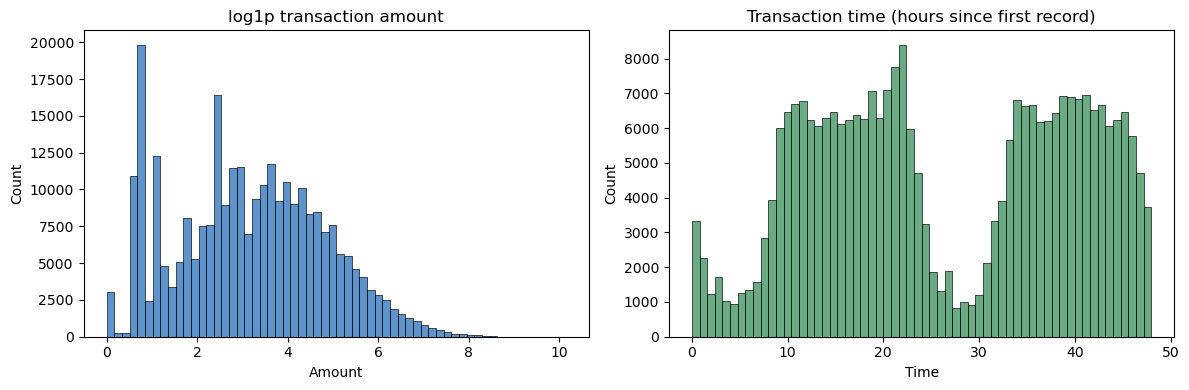

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(np.log1p(df['Amount']), bins=60, ax=axes[0], color='#2a6fbb')
axes[0].set_title('log1p transaction amount')
sns.histplot(df['Time']/3600, bins=60, ax=axes[1], color='#3a8f5b')
axes[1].set_title('Transaction time (hours since first record)')
plt.tight_layout(); plt.show()

## 3. Preparation

The PCA variables are already transformed. `Amount` receives `log1p` to reduce extreme right-skew, then `Time` and transformed `Amount` are robust-scaled. This prevents these two non-PCA features from dominating Euclidean distances. No target-based resampling is performed because the models are fitted without labels.

In [15]:
y = df['Class'].astype(int).to_numpy()
feature_cols = [c for c in df.columns if c != 'Class']
X_df = df[feature_cols].copy()
X_df['Amount'] = np.log1p(X_df['Amount'])
X = X_df.to_numpy(dtype='float32')
for col in ['Time','Amount']:
    j = feature_cols.index(col)
    X[:, j] = RobustScaler().fit_transform(X[:, [j]]).ravel()
print('Modelling matrix:', X.shape)
assert 'Class' not in feature_cols

Modelling matrix: (284807, 30)


## 4. Statistical outlier baseline

A robust z-score uses the median and median absolute deviation (MAD), avoiding the sensitivity of mean/standard deviation to extreme transactions. The baseline combines a high feature-wise robust deviation with the overall multivariate robust norm. It is deliberately simple and interpretable: transactions rank higher when they are unusual on one or several dimensions.

In [16]:
median = np.median(X, axis=0)
mad = np.median(np.abs(X - median), axis=0)
mad = np.where(mad < 1e-9, 1.0, mad)
robust_z = np.abs((X - median) / (1.4826 * mad))
statistical_score = np.maximum(np.quantile(robust_z, 0.95, axis=1),
                               np.linalg.norm(robust_z, axis=1) / np.sqrt(X.shape[1]))
print(pd.Series(statistical_score).describe(percentiles=[.95,.99,.999]))

count    284807.000000
mean          2.476515
std           2.540889
min           0.716419
50%           1.932218
95%           5.345819
99%          12.721476
99.9%        32.197434
max         191.622162
dtype: float64


## 5. Cluster-based anomaly score

MiniBatch K-means is chosen because 284,807 rows make full repeated K-means unnecessarily expensive. Forty micro-clusters approximate several local transaction regimes. A transaction's anomaly score is its distance to the assigned centroid divided by the median distance within that cluster. This normalization avoids automatically labelling members of naturally diffuse clusters as anomalous.

In [17]:
cluster_model = MiniBatchKMeans(n_clusters=40, batch_size=4096,
                                      n_init=10, random_state=RANDOM_STATE)
cluster_id = cluster_model.fit_predict(X)
distance = np.linalg.norm(X - cluster_model.cluster_centers_[cluster_id], axis=1)
cluster_scale = pd.Series(distance).groupby(cluster_id).transform('median').to_numpy()
cluster_score = distance / np.maximum(cluster_scale, 1e-9)

## 6. Classification-based anomaly detector

Isolation Forest is a tree-based anomaly classifier. It repeatedly partitions randomly selected features and values; observations isolated in fewer splits receive higher anomaly scores. It is suitable here because it scales to large numeric data, captures non-linear interactions, and does not require fraud labels. Its limitation is that rare but legitimate behaviour can also be isolated quickly.

In [18]:
iforest = IsolationForest(n_estimators=300, max_samples=8192,
                          contamination='auto', n_jobs=-1,
                          random_state=RANDOM_STATE)
iforest.fit(X)
isolation_score = -iforest.score_samples(X)

## 7. Ranking evaluation against withheld labels

PR-AUC summarizes performance where positive cases are rare. ROC-AUC is included for completeness but can look optimistic under extreme imbalance. At-K metrics translate the ranking into an investigation queue:

- **Precision@K:** proportion of reviewed transactions that are fraud.
- **Recall@K:** proportion of all frauds captured within the queue.
- **Lift@K:** Precision@K divided by the background fraud prevalence.

`K=492` is especially interpretable because it equals the number of known fraud cases, while 100, 250 and 1,000 represent alternative review capacities.

In [19]:
def ranking_metrics(y, scores, ks=(100,250,492,1000)):
    order = np.argsort(scores)[::-1]
    out = {'PR_AUC': average_precision_score(y, scores),
           'ROC_AUC': roc_auc_score(y, scores)}
    for k in ks:
        hits = int(y[order[:k]].sum())
        out[f'Frauds@{k}'] = hits
        out[f'Precision@{k}'] = hits/k
        out[f'Recall@{k}'] = hits/y.sum()
        out[f'Lift@{k}'] = (hits/k)/y.mean()
    return out

scores = {'Statistical baseline': statistical_score,
          'Cluster distance': cluster_score,
          'Isolation Forest': isolation_score}
results = pd.DataFrame({name: ranking_metrics(y, s) for name,s in scores.items()}).T
display(results.style.format(precision=4))

,PR_AUC,ROC_AUC,Frauds@100,Precision@100,Recall@100,Lift@100,Frauds@250,Precision@250,Recall@250,Lift@250,Frauds@492,Precision@492,Recall@492,Lift@492,Frauds@1000,Precision@1000,Recall@1000,Lift@1000
Statistical baseline,0.0478,0.9410,9.0000,0.0900,0.0183,52.0988,15.0000,0.0600,0.0305,34.7326,20.0000,0.0407,0.0407,23.5315,93.0000,0.0930,0.1890,53.8355
Cluster distance,0.1301,0.7714,24.0000,0.2400,0.0488,138.9302,81.0000,0.3240,0.1646,187.5558,148.0000,0.3008,0.3008,174.1334,194.0000,0.1940,0.3943,112.3019
Isolation Forest,0.2886,0.9544,65.0000,0.6500,0.1321,376.2694,119.0000,0.4760,0.2419,275.5450,171.0000,0.3476,0.3476,201.1947,255.0000,0.2550,0.5183,147.6134


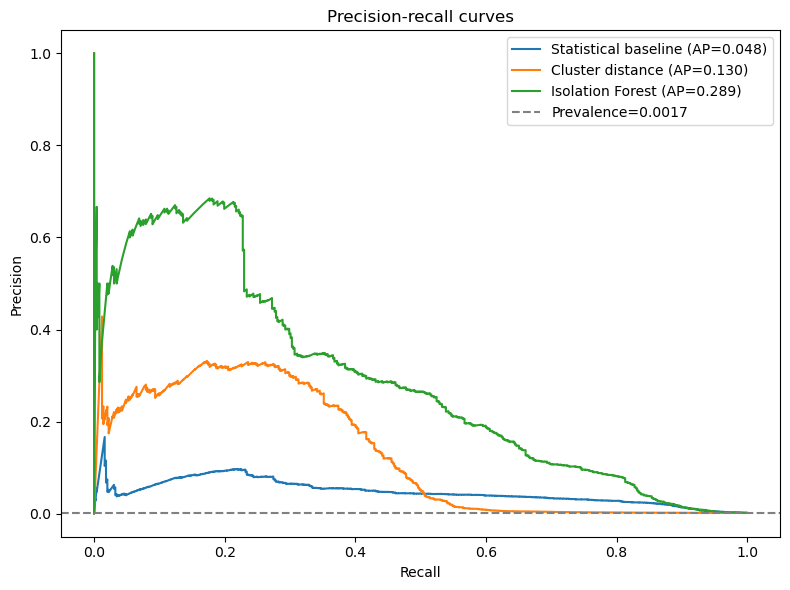

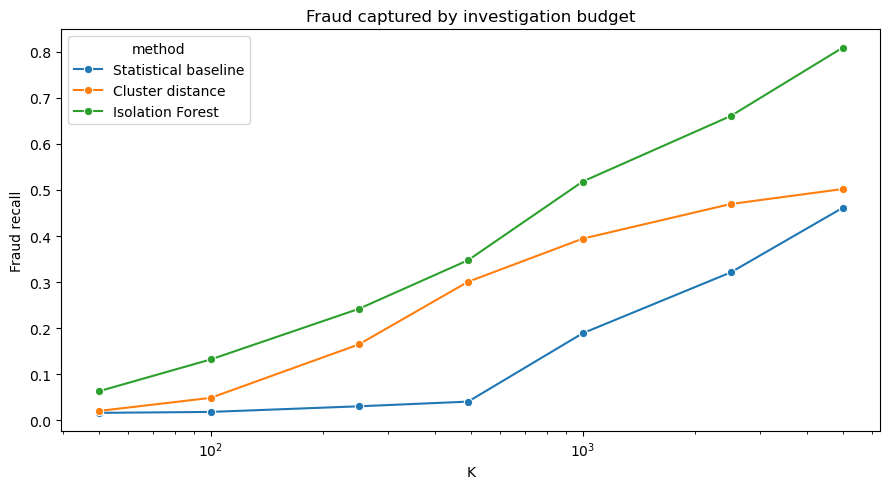

In [20]:
plt.figure(figsize=(8,6))
for name, s in scores.items():
    precision, recall, _ = precision_recall_curve(y, s)
    plt.plot(recall, precision, label=f'{name} (AP={average_precision_score(y,s):.3f})')
plt.axhline(y.mean(), color='gray', linestyle='--', label=f'Prevalence={y.mean():.4f}')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-recall curves')
plt.legend(); plt.tight_layout(); plt.show()

budget_rows=[]
for name,s in scores.items():
    order=np.argsort(s)[::-1]; cum=np.cumsum(y[order])
    for k in [50,100,250,492,1000,2500,5000]:
        budget_rows.append({'method':name,'K':k,'recall':cum[k-1]/y.sum()})
budget=pd.DataFrame(budget_rows)
plt.figure(figsize=(9,5)); sns.lineplot(data=budget,x='K',y='recall',hue='method',marker='o')
plt.xscale('log'); plt.ylabel('Fraud recall'); plt.title('Fraud captured by investigation budget')
plt.tight_layout(); plt.show()

## 8. Sensitivity and robustness

Isolation Forest contains randomness. Repeating the model across several seeds tests whether the conclusion depends on one random state. A robust choice should show similar PR-AUC, ROC-AUC and Recall@492. A production study should extend this to alternative `max_samples`, feature subsets, rolling time windows and cost-weighted review budgets.

In [21]:
sensitivity=[]
for seed in [7,21,42]:
    model=IsolationForest(n_estimators=150,max_samples=8192,contamination='auto',
                          n_jobs=-1,random_state=seed).fit(X)
    s=-model.score_samples(X); order=np.argsort(s)[::-1]
    sensitivity.append({'seed':seed,'PR_AUC':average_precision_score(y,s),
                        'ROC_AUC':roc_auc_score(y,s),
                        'Recall@492':y[order[:492]].sum()/y.sum()})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.style.format(precision=4))

,seed,PR_AUC,ROC_AUC,Recall@492
0,7,0.2672,0.9538,0.3130
1,21,0.2572,0.9532,0.3313
2,42,0.2795,0.9554,0.3293


## 9. Decision and operational recommendation

I'd Recommend to Select the method that produces the strongest and most stable **top-of-list fraud retrieval**, particularly PR-AUC and Recall@K at the realistic review budget. If Isolation Forest leads, it should become the primary ranking model, with the statistical and cluster scores retained as challenger models and explanatory signals.

A practical workflow is:

1. Score new transactions and place the highest-risk items in a review queue.
2. Set `K` from investigator capacity and expected loss, not from an arbitrary anomaly threshold.
3. Display the transaction amount, time, anomaly percentile and which method(s) flagged it.
4. Record investigator outcomes and delays, then monitor precision, recall proxy measures, alert volume and model drift.
5. Use step-up verification rather than automatic decline where the cost of false positives is high.

Because `Amount` is available, future work should evaluate **value-weighted recall**: the proportion of fraudulent euros captured, not only the number of fraudulent transactions.

## 10. Why unusual does not necessarily mean fraudulent

An anomaly detector identifies rarity relative to the observed feature distribution, while fraud is a behavioural and legal label. A legitimate customer may make an unusually large purchase, travel, buy at a new time, or change normal spending patterns. Conversely, sophisticated fraud can imitate common transactions and remain close to dense regions. The two concepts overlap, but they are not equivalent.

This distinction has operational consequences. An anomaly score should trigger proportionate investigation or verification, not an accusation. False positives can block genuine purchases, inconvenience customers and create unequal burdens for people whose legitimate behaviour is uncommon in the historical data.

## 11. Limitations and responsible application

The dataset covers only two days and contains anonymized PCA components, limiting substantive explanation and temporal validation. Labels may reflect the fraud-detection process operating at the time, and concept drift can make 2013 patterns less representative of later behaviour. Evaluating on the same period used for unsupervised fitting is acceptable for descriptive ranking comparison, but a production design should fit on earlier transactions and evaluate on later ones. The system should support human review, secure data handling, appeal routes and regular monitoring of false-positive impact.

## References

- Davis, J., & Goadrich, M. (2006). The relationship between Precision-Recall and ROC curves. *Proceedings of ICML*, 233-240.
- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *Proceedings of ICDM*, 413-422.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432.
- Schölkopf, B., Platt, J. C., Shawe-Taylor, J., Smola, A. J., & Williamson, R. C. (2001). Estimating the support of a high-dimensional distribution. *Neural Computation, 13*(7), 1443-1471.